saved figures/cost_compute_P2.png


saved figures/cost_compute_P2.svg


saved figures/cost_compute_P10.png


saved figures/cost_compute_P10.svg


saved figures/memory_traffic_P2.png


saved figures/memory_traffic_P2.svg


saved figures/memory_traffic_P10.png


saved figures/memory_traffic_P10.svg


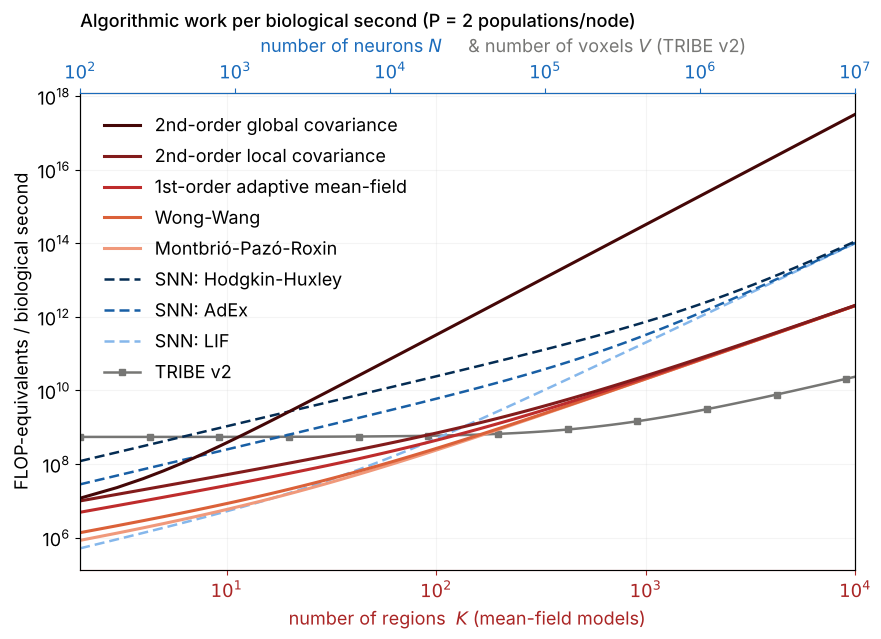

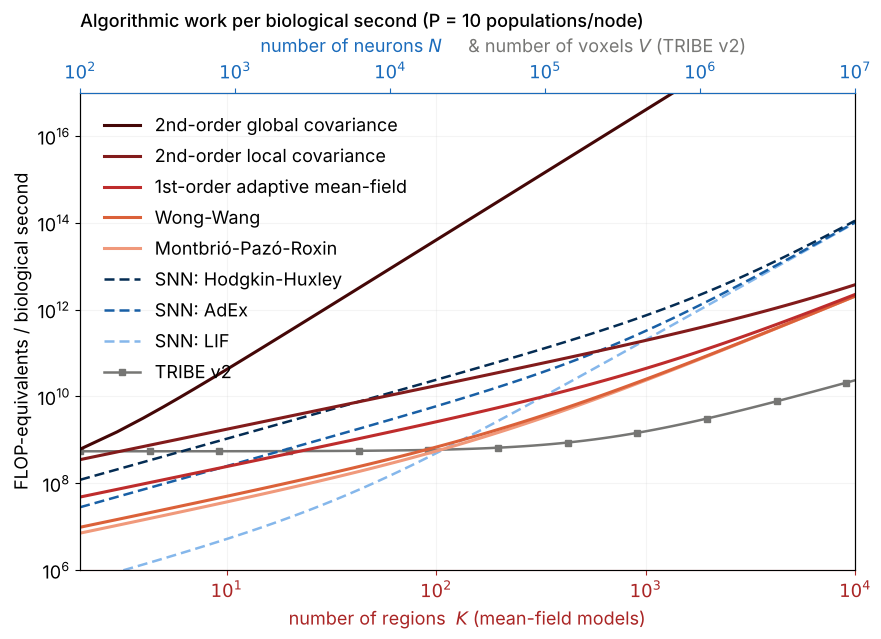

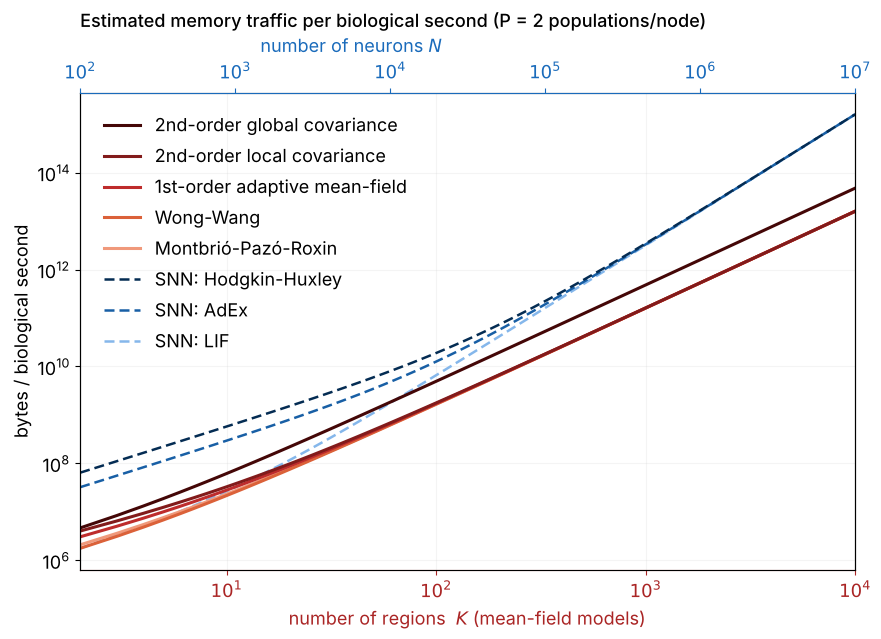

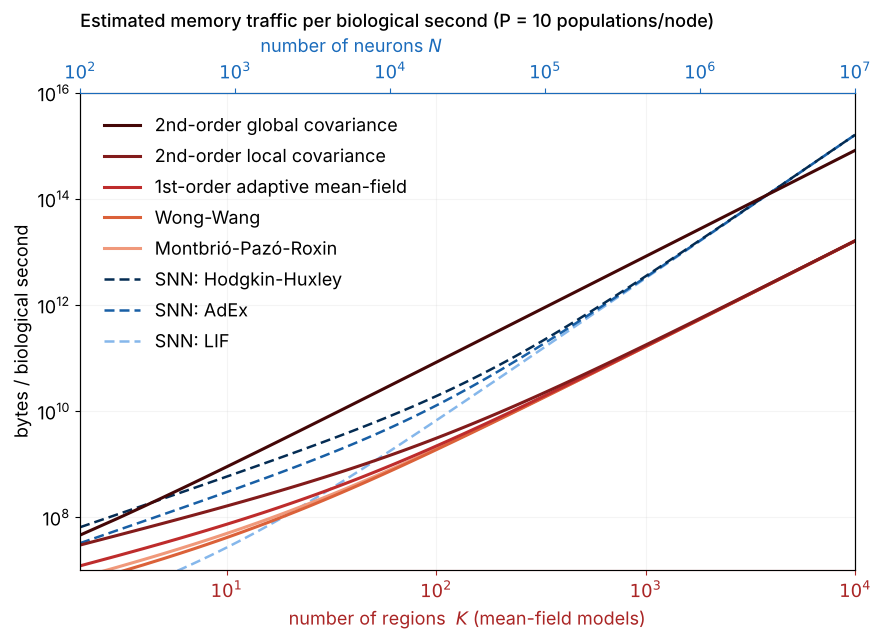

In [1]:
"""
Project: Mechanistic bridges from receptors to whole-brain dynamics: promise
and limits of master-equation mean-field models (arXiv:2608.00306)
Date: 19/10/2026
Authors: YBossard + Claude Opus 4.8

FLOP-equivalent and streaming-access proxies for whole-brain model classes.
"""

import os
import numpy as np
import matplotlib.pyplot as plt

OUTDIR = 'figures'          # PNG and SVG files are written here
os.makedirs(OUTDIR, exist_ok=True)

def save_fig(fig, name):
    """Save a figure as PNG and SVG in OUTDIR."""
    for ext in ('png', 'svg'):
        path = os.path.join(OUTDIR, f'{name}.{ext}')
        fig.savefig(path, bbox_inches='tight', dpi=200)
        print('saved', path)




# ============================================================
#  Algorithmic cost / memory of whole-brain model classes.
#    bottom  K (regions)  -> mean-field models      [RED ramp]
#    top     N (neurons)  -> spiking networks        [BLUE ramp]
#                          + V (voxels) for TRIBE     [GRAY]
#  Color ties each curve to the axis it is read against.
#  Horizontal position is NOT comparable across color families.
# ============================================================
steps = 1e4          # T_bio / dt at dt = 0.1 ms
rho   = 1.0          # dense connectome (mesoscopic panel)

RED = {'mpr':'#F0997B', 'ww':"#DB6139", 'first':"#BE2C2C", 'local':"#821B1B", 'glob':"#440707"}
BLUE = {'LIF':'#85B7EB', 'Izhikevich':'#378ADD',
        'AdEx':'#185FA5', 'Hodgkin-Huxley':'#042C53'}
GRAY_TRIBE = "#767674"
AX_RED, AX_BLUE, AX_GRAY = "#AA2525", "#1A6BBB", "#767674"

K_MIN, K_MAX = 2,   1e4
N_MIN, N_MAX = 1e2, 1e7
V_MIN, V_MAX = N_MIN, N_MAX

def to_frac(x, xmin, xmax):
    return (np.log10(x) - np.log10(xmin)) / (np.log10(xmax) - np.log10(xmin))

# ---- cost models (FLOP-eq / biological second) ----
def meso_costs(P):
    R = P*(P+1)/2
    Wnode1st      = 15*P**2 + 86*P
    Wder          = 13 + 14*P + 18*R
    Wnode2ndLocal = Wnode1st + P*Wder + P*(2*R+1) + (R*(4*P+4) + 3*P)
    return dict(
        mpr   = lambda K: steps*((2*P**2 + 15*P)*K + 2*rho*K**2),
        ww    = lambda K: steps*((2*P**2 + 28*P)*K + 2*rho*K**2),
        first = lambda K: steps*((15*P**2 + 90*P)*K + 2*rho*K**2),
        local = lambda K: steps*(Wnode2ndLocal*K + 2*rho*K**2 + K*(4*P+2*R)),
        glob  = lambda K: steps*(Wnode1st*K + Wder*(P*K)
                                 + 2*rho*(P*K)**2 + 4*rho*(P*K)**3
                                 + 2*rho*K**2 + 2*(2*P*K + (P*K)*(P*K+1)/2)),
    )

SNN_dict = {'LIF':(5,1e-3), 'Izhikevich':(13,1e-3),
       'AdEx':(28,0.1e-3), 'Hodgkin-Huxley':(120,0.1e-3)}
W_snn = lambda c, dt, N: (c/dt)*N + N**2

#D_MODEL, F_STIM, F_FMRI, N_BACK = 1152, 2, 1, 5e9
#W_tribe = lambda V: 2*F_STIM*N_BACK + 2*F_FMRI*D_MODEL*V

# ---- TRIBE v2 cached-feature -> fMRI proxy ----
# Paper-described architecture:
#   - three cached modalities at 2 Hz;
#   - three grouped layer representations per modality;
#   - each modality projected to 384 dimensions;
#   - concatenated D_model = 1152;
#   - eight transformer layers over a non-overlapping 100-s window;
#   - direct D_model x N_targets subject head at 1-Hz fMRI output.
#
# The released code also supports a low-rank head; that implementation-specific
# path is deliberately not mixed into this paper-level proxy.
D_MODEL = 1152
D_MODALITY_OUT = 384
N_LAYER_GROUPS = 3
FEATURE_DIMS = {"text": 2048, "audio": 1024, "video": 1280}
N_PROJ = N_LAYER_GROUPS * D_MODALITY_OUT * sum(FEATURE_DIMS.values())

N_LAYER = 8
F_STIM = 2.0
F_FMRI = 1.0
T_CONTEXT = 100.0
N_CONTEXT = int(F_STIM * T_CONTEXT)

# Standard dense-transformer parameter proxy: 4 D^2 for Q/K/V/output
# projections and 8 D^2 for a width-4D feed-forward block, per layer.
N_TRANSFORMER = 12 * N_LAYER * D_MODEL**2


def tribe_cached_cost(n_targets):
    """Naive paper-level FLOP-equivalent proxy per biological second.

    Assumes one non-overlapping 100-s context-window evaluation, amortized over
    the same 100 s. Counts multiply-add as two FLOP-equivalents. It neglects
    biases, normalization, activations, softmax, pooling, data movement, and
    the offline raw-stimulus encoders.
    """
    dense_parameter_work = 2 * F_STIM * (N_PROJ + N_TRANSFORMER)
    attention_matrix_work = (
        4 * N_LAYER * (N_CONTEXT**2 / T_CONTEXT) * D_MODEL
    )
    output_head_work = 2 * F_FMRI * D_MODEL * n_targets
    return dense_parameter_work + attention_matrix_work + output_head_work




# ---- memory traffic (bytes / biological second) ----
def meso_mem(P):
    R = P*(P+1)/2
    return dict(
        mpr   = lambda K: 8*steps*((4*P+1)*K + 2*rho*K**2),
        ww    = lambda K: 8*steps*((3*P+1)*K + 2*rho*K**2),
        first = lambda K: 8*steps*((7*P+1)*K + 2*rho*K**2),
        local = lambda K: 8*steps*((7*P+2*R+1)*K + 2*rho*K**2),
        glob  = lambda K: 8*steps*((7*P+1)*K + 2*(P*K)*(P*K+1)/2 + 2*rho*K**2),
    )
C_states = {'LIF':2, 'Izhikevich':4, 'AdEx':4, 'Hodgkin-Huxley':8}
M_snn   = lambda cs, dt, N: 8*cs*N/dt + 16*N**2
#M_tribe = lambda V: 2*(N_BACK + D_MODEL*V)

MESO = [('mpr','Montbrió-Pazó-Roxin',None), ('ww','Wong-Wang',None), ('first','1st-order adaptive mean-field',None),
        ('local','2nd-order local covariance',None), ('glob','2nd-order global covariance',None)]

def log_ticks(xmin, xmax):
    lo, hi = int(np.floor(np.log10(xmin))), int(np.ceil(np.log10(xmax)))
    return [10**e for e in range(lo, hi+1) if xmin <= 10**e <= xmax]

# ============================================================
#  One standalone figure per (P, kind).
# ============================================================
def make_figure(P, kind, ylim=None):
    fig, ax = plt.subplots(figsize=(10, 6.2))   # wider single panel

    K = np.unique(np.round(np.logspace(np.log10(K_MIN), np.log10(K_MAX), 90)))
    N = np.unique(np.round(np.logspace(np.log10(N_MIN), np.log10(N_MAX), 90)))
    V = np.unique(np.round(np.logspace(np.log10(V_MIN), np.log10(V_MAX), 90)))

    if kind == 'compute':
        meso = meso_costs(P)
        snn_y  = lambda lbl: W_snn(SNN_dict[lbl][0], SNN_dict[lbl][1], N)
        tribe_y = tribe_cached_cost(V)
        ylabel = 'FLOP-equivalents / biological second'
    else:
        meso = meso_mem(P)
        snn_y  = lambda lbl: M_snn(C_states[lbl], SNN_dict[lbl][1], N)
        #tribe_y = M_tribe(V)
        ylabel = 'bytes / biological second'

    handles = {}   # keyed by label, filled in plot order, reordered for the legend

    # TRIBE (GRAY, dotted) vs V  -- drawn first (bottom of z-order)
    if kind == 'compute':
      (handles['TRIBE v2'],) = ax.plot(
          to_frac(V, V_MIN, V_MAX), tribe_y,
          color=GRAY_TRIBE, lw=1.8, ls='-', marker='s', markersize=5, markevery=8,
          label='TRIBE v2')

    # spiking (BLUE, dashed) vs N  -- drawn on top of TRIBE
    for lbl in SNN_dict:
        if lbl == 'Izhikevich':  # skip Izhikevich for clarity
            continue
        (handles['SNN: '+lbl],) = ax.plot(
            to_frac(N, N_MIN, N_MAX), snn_y(lbl),
            color=BLUE[lbl], lw=1.8, ls=(0,(4,2)), label='SNN: '+lbl)

    # mean-field (RED) vs K  -- drawn last (top of z-order)
    for key, label, dash in MESO:
        (handles[label],) = ax.plot(
            to_frac(K, K_MIN, K_MAX), meso[key](K),
            color=RED[key], lw=2.2, ls='-' if dash is None else dash, label=label)

    ax.set_yscale('log')
    ax.set_xlim(0, 1)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel, fontsize=13)
    TICK_SIZE = 13

    if kind == 'compute':
        title = f'Algorithmic work per biological second (P = {P} populations/node)'
    else:
        title = f'Estimated memory traffic per biological second (P = {P} populations/node)'
    ax.set_title(title, loc='left', fontsize=13, fontweight='medium')

    ax.grid(True, which='both', alpha=0.13)

    # bottom axis: K (RED)
    kt = log_ticks(K_MIN, K_MAX)
    ax.set_xticks([to_frac(k, K_MIN, K_MAX) for k in kt])
    ax.set_xticklabels([f'$10^{{{int(np.log10(k))}}}$' for k in kt])
    ax.set_xlabel('number of regions  $K$ (mean-field models)', color=AX_RED, fontsize=13)
    ax.tick_params(axis='x', colors=AX_RED, labelsize=TICK_SIZE)
    ax.tick_params(axis='y', labelsize=13)
    ax.spines['bottom'].set_color(AX_RED)

    # top axis: N (BLUE) + gray voxel note
    axN = ax.twiny()
    axN.set_xlim(0, 1)
    nt = log_ticks(N_MIN, N_MAX)
    axN.set_xticks([to_frac(n, N_MIN, N_MAX) for n in nt])
    axN.set_xticklabels([f'$10^{{{int(np.log10(n))}}}$' for n in nt])
    axN.tick_params(axis='x', colors=AX_BLUE, labelsize=TICK_SIZE)
    axN.spines['top'].set_color(AX_BLUE)
    axN.set_xlabel(' ', color=AX_BLUE, fontsize=13, labelpad=6)
    axN.annotate('number of neurons $N$',
                 xy=(0.35, 1.0), xycoords='axes fraction',
                 xytext=(0, 26), textcoords='offset points',
                 ha='center', va='bottom', fontsize=13, color=AX_BLUE)
    if kind == 'compute':   # TRIBE v2 is drawn on the compute figures only
        axN.annotate('& number of voxels $V$ (TRIBE v2)',
                     xy=(0.68, 1.0), xycoords='axes fraction',
                     xytext=(0, 26), textcoords='offset points',
                     ha='center', va='bottom', fontsize=13, color=AX_GRAY)

    # ----- legend in explicit order (independent of plot/z-order) -----
    legend_order = [
        '2nd-order global covariance',
        '2nd-order local covariance',
        '1st-order adaptive mean-field',
        'Wong-Wang',
        'Montbrió-Pazó-Roxin',
        'SNN: Hodgkin-Huxley',
        'SNN: AdEx',
        'SNN: LIF',
        'TRIBE v2',
    ]
    ordered = [handles[k] for k in legend_order if k in handles]
    ax.legend(ordered, [h.get_label() for h in ordered],
              fontsize=13, frameon=False, loc='upper left', bbox_to_anchor=(0.01, 0.99))
    fig.subplots_adjust(top=0.88)
    return fig

# ============================================================
#  Build and save the four figures.
#  P=10 global covariance can dwarf the rest -> clamp y-range.
# ============================================================
savefig_bool = True
if savefig_bool:
  save_fig(make_figure(2,  'compute'),                         'cost_compute_P2')
  save_fig(make_figure(10, 'compute', ylim=(1e6, 1e17)),       'cost_compute_P10')
  save_fig(make_figure(2,  'memory'),                          'memory_traffic_P2')
  save_fig(make_figure(10, 'memory',  ylim=(1e7, 1e16)),       'memory_traffic_P10')

plt.show()

### Numbers quoted in the text

The cell below recomputes, with the functions used for the figures, the numbers quoted in the main text and in the Supplementary section *Algorithmic cost analysis for neural simulation* (E/I node: $P=P_w=2$, $\rho=1$, $10^4$ Euler steps per biological second).

In [2]:
P = 2
R = P*(P+1)//2
W_der = 13 + 14*P + 18*R                     # analytic derivatives, per population
W_c = R*(4*P + 4) + 3*P                      # covariance equations of one node
W_node = {'mpr': 2*P**2 + 11*P, 'ww': 2*P**2 + 26*P, 'first': 15*P**2 + 86*P}
W_node['local'] = W_node['first'] + P*W_der + P*(2*R + 1) + W_c
print('Node-local RHS cost (FLOP-eq):', W_node, '| W_der =', W_der,
      '| first order with P_w = 1:', 15*P**2 + 80*P + 6,
      '| finite-difference second order ~', (1 + 2*P**2)*W_node['first'])

work, mem = meso_costs(P), meso_mem(P)
for key in ['mpr', 'ww', 'first', 'local']:
    w = work[key](1.0)/steps - 2*rho         # coefficient of K in W_1s / 1e4
    m = mem[key](1.0)/(8*steps) - 2*rho      # coefficient of K in M_1s / 8e4
    print(f'{key:>5}: W_1s = 1e4 [{w:.0f} K + 2 K^2],  M_1s = 8e4 [{m:.0f} K + 2 K^2] bytes,  '
          f'node-local W/M = {w/(8*m):.2f} FLOP-eq/byte,  connectome traffic dominates for K > {m/2:.1f}')

clock = {lbl: c/dt for lbl, (c, dt) in SNN_dict.items()}   # FLOP-eq per neuron and biological second
print('\nSNN clock cost per neuron and biological second (= crossover size N*):',
      {lbl: f'{v:.2g}' for lbl, v in clock.items()},
      '| Hodgkin-Huxley / LIF: per step', SNN_dict['Hodgkin-Huxley'][0]/SNN_dict['LIF'][0],
      ', per biological second', clock['Hodgkin-Huxley']/clock['LIF'])

W0 = tribe_cached_cost(0)
print(f'\nTRIBE v2: N_proj = {N_PROJ:.3g}, N_tr = {N_TRANSFORMER:.3g}, target-independent work = {W0:.3g}')
for name, n in [('cortex', 20484), ('subcortex', 8802)]:
    print(f'  {name:>9}: readout {tribe_cached_cost(n) - W0:.3g}, total {tribe_cached_cost(n):.3g} '
          f'FLOP-eq per second of stimulus, fp16 weights {2*(N_PROJ + N_TRANSFORMER + D_MODEL*n)/1e6:.0f} MB')

K_reg = 50                                   # regional SNNs versus 50-node mean-field networks
print(f'\nK = 50 regions: mean-field {work["mpr"](K_reg)/1e9:.2f} (MPR) to {work["local"](K_reg)/1e9:.2f} '
      '(2nd-order local) x 1e9 FLOP-eq per biological second')
for lbl in ['LIF', 'AdEx']:
    c, dt = SNN_dict[lbl]
    print(f'  regional SNN ({lbl}): ' + ', '.join(f'n = {n:.0e}: {K_reg*W_snn(c, dt, n)/1e9:.3g} x 1e9'
                                                for n in (1e3, 1e4)))

Node-local RHS cost (FLOP-eq): {'mpr': 30, 'ww': 60, 'first': 232, 'local': 478} | W_der = 95 | first order with P_w = 1: 226 | finite-difference second order ~ 2088
  mpr: W_1s = 1e4 [38 K + 2 K^2],  M_1s = 8e4 [9 K + 2 K^2] bytes,  node-local W/M = 0.53 FLOP-eq/byte,  connectome traffic dominates for K > 4.5
   ww: W_1s = 1e4 [64 K + 2 K^2],  M_1s = 8e4 [7 K + 2 K^2] bytes,  node-local W/M = 1.14 FLOP-eq/byte,  connectome traffic dominates for K > 3.5
first: W_1s = 1e4 [240 K + 2 K^2],  M_1s = 8e4 [15 K + 2 K^2] bytes,  node-local W/M = 2.00 FLOP-eq/byte,  connectome traffic dominates for K > 7.5
local: W_1s = 1e4 [492 K + 2 K^2],  M_1s = 8e4 [21 K + 2 K^2] bytes,  node-local W/M = 2.93 FLOP-eq/byte,  connectome traffic dominates for K > 10.5

SNN clock cost per neuron and biological second (= crossover size N*): {'LIF': '5e+03', 'Izhikevich': '1.3e+04', 'AdEx': '2.8e+05', 'Hodgkin-Huxley': '1.2e+06'} | Hodgkin-Huxley / LIF: per step 24.0 , per biological second 240.0

TRIBE v2: N_pr